# Learned action policies: state of the art

**Level:** 3  
**Prerequisites:** Learned action policies level 1  
**Reading time:** 25 minutes

**Question:** Does the same-case comparison support a learned-policy advantage over the guarded deterministic baseline?


## Objectives

For level 3 of learned action scoring on C05, Follow candidate features from an observed C05 state into a fitted scorer. For level 3 of learned action scoring on C05, The lesson separates the learned preference from the admissibility mask and the independent task verifier, so probability, action authority and task success remain different quantities.


## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
For level 3 of learned action scoring on C05, The notebook reads committed product artifacts. For level 3 of learned action scoring on C05, Owner: For level 3 of learned action scoring on C05, Neuraxis. For level 3 of learned action scoring on C05, Repository: For level 3 of learned action scoring on C05, https://github.com/fsantibanezleal/CAOS_Neuraxis. License: For level 3 of learned action scoring on C05, Apache-2.0. For level 3 of learned action scoring on C05, The JSON is a first-party, frozen experiment artifact; For level 3 of learned action scoring on C05, no external benchmark data are redistributed in this notebook.

For level 3 of learned action scoring on C05, This notebook reads `data/derived/index.json` and the listed trace artifacts. For level 3 of learned action scoring on C05, The method run uses an isolated Reflexmesh case workspace. For level 3 of learned action scoring on C05, For learned methods, fetch the exact public release assets with `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder. For level 3 of learned action scoring on C05, The release manifest verifies asset hashes. For level 3 of learned action scoring on C05, Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model.

For level 3 of learned action scoring on C05, Artifacts for this lesson:

- `data/derived/index.json`
- `data/derived/benchmark-adequacy.json`
- `data/derived/episodes/M03-C05-nominal-40000.json`
- `data/derived/episodes/M04-C05-nominal-40000.json`


## Method

For level 3 of learned action scoring on C05, A candidate scorer maps each admissible candidate's features to a preference; For level 3 of learned action scoring on C05, calibration changes the interpretation of scores but does not establish causal benefit. For level 3 of learned action scoring on C05, The M03 logistic model and M04 boosted-tree model inherit the training distribution, label construction and held-out split. For level 3 of learned action scoring on C05, Their action output is still checked against the current admissible set before execution. For level 3 of learned action scoring on C05, This distinction matters when one candidate has a high predicted probability but an expired resource revision or missing capability. For level 3 of learned action scoring on C05, The example uses a single frozen C05 observation to make the feature-to-choice path inspectable. For level 3 of learned action scoring on C05, Its result cannot measure calibration quality; For level 3 of learned action scoring on C05, that requires the held-out calibration records and a reliability analysis across independent groups. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, A fitted classifier estimates preference from features and labels, whereas the admissibility mask remains a runtime safety constraint. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, probability calibration and legal action selection are separate measurable properties. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, The C05 replay is useful for tracing feature construction and score ranking, but a learner can memorize task identifiers unless split design withholds relevant compositions and reports the held-out denominator. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, Learning value is clearest where the fixed policy makes a consequential error and the learner corrects it on fresh conditions. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, a benchmark saturated by deterministic rules cannot demonstrate that advantage. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, Compare action ranking, task completion and controller cost separately, then inspect false positives and false negatives against the independent task oracle rather than treating accuracy as the product outcome. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, Repeated seed outcomes do not create independent evidence when the environment and policy are deterministic. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, meaningful uncertainty needs outcome variation or a justified resampling unit at the task-family level. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, For this level, inspect the candidate features and the learned score together, then verify that the chosen action was admissible before attributing the outcome to model quality. For level 3 of learned action scoring on C05, At level 3, for learned action scoring on C05, A useful extension holds out an entire task composition, evaluates calibration on fresh cases, and compares the learner with the deterministic baseline on the same episodes.


### learned action scoring · level 3 — Verify the audit and each trace's bytes before interpreting outcomes.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M03", "M04"]
trace_methods = ["M03", "M04"]
sample_case = "C05"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 2


### learned action scoring · level 3 — Execute the released policies and compare the run


### learned action scoring · level 3 — Compare the full sequence, not only the first action


### learned action scoring · level 3 — Recompute per-variant outcomes from every trace in the case


In [3]:
# Read every seed for the selected case and keep each failed episode in the denominator.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M03 boundary successes= 10 episodes= 10 rate= 1.0
M03 delayed_observation successes= 10 episodes= 10 rate= 1.0
M03 duplicate_event successes= 10 episodes= 10 rate= 1.0
M03 nominal successes= 10 episodes= 10 rate= 1.0
M03 stale_conflict successes= 10 episodes= 10 rate= 1.0
M03 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M04 boundary successes= 10 episodes= 10 rate= 1.0
M04 delayed_observation successes= 10 episodes= 10 rate= 1.0
M04 duplicate_event successes= 10 episodes= 10 rate= 1.0
M04 nominal successes= 10 episodes= 10 rate= 1.0
M04 stale_conflict successes= 10 episodes= 10 rate= 1.0
M04 unavailable_dependency successes= 10 episodes= 10 rate= 1.0


### Plot the variant stress without pooling families


In [4]:
# Each point summarizes the seeds from one case variant, not the full benchmark.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified success rate")
ax.set_title(sample_case + " by variant")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
display(fig)
plt.close(fig)


<Figure size 900x450 with 1 Axes>

### learned action scoring · L3 — Build the first executable policy

In level 3, construct policy M03 for learned action scoring with the public factory and keep its observation contract unchanged before sampling C05.


In [5]:
# Construct the first released policy through the public factory.
primary_id = "M03"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M03


### learned action scoring · L3 — Execute the primary method on the named case

At level 3, the learned action scoring evaluator runs M03 on C05 and derives success from the independent task postcondition, not from a replayed trace.


In [6]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### learned action scoring · L3 — Construct an independent comparison policy

For level 3 of learned action scoring, create M04 as a fresh object so recurrent state from M03 cannot leak into the matched comparison.


In [7]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### learned action scoring · L3 — Run the comparison under identical conditions

This level 3 comparison runs M04 on the same C05, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.


In [8]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### learned action scoring · L3 — Aggregate the two executed episodes

At level 3, the package aggregator summarizes two executed learned action scoring episodes, and cross-family claims still require the complete benchmark below.


In [9]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### learned action scoring · L3 — Fresh policy outcomes

For level 3 of learned action scoring on C05, The next plot is computed from the learned action scoring episode results just executed for C05 rather than copied from a frozen artifact.


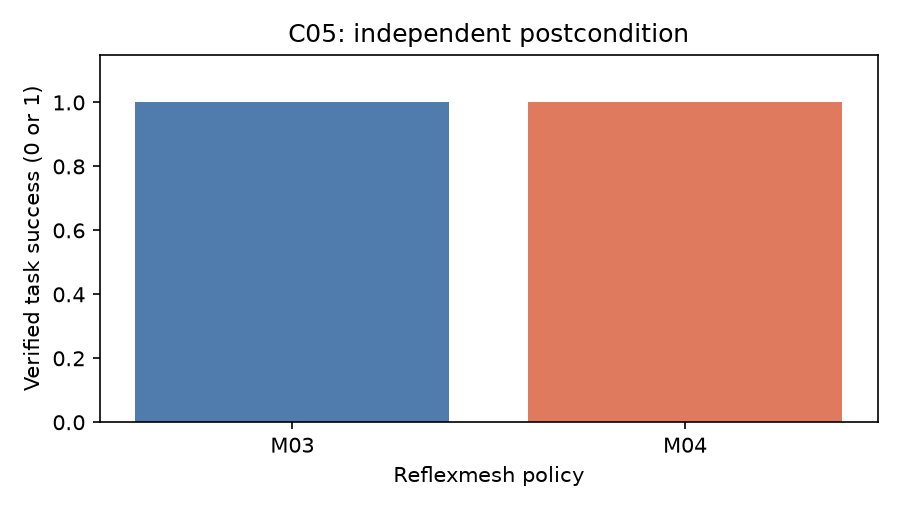

In [10]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For level 3 of learned action scoring on C05, For learned action scoring, these bars show fresh task-postcondition outcomes for M03 and M04 on C05, with success encoded as 1 and failure as 0. For level 3 of learned action scoring on C05, Read the case and seed before comparing them. For level 3 of learned action scoring on C05, This controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks.


## State of the art

At level 3, for learned action scoring on C05, Logistic regression and gradient-boosted trees are established supervised methods, while calibration evaluates how scores relate to observed outcomes. At level 3, for learned action scoring on C05, This comparison executes M04 on the same C05 case and displays the M03/M04 runs separately from the frozen matrix. At level 3, for learned action scoring on C05, A single episode cannot establish calibration, which requires held-out probability bins and a proper scoring rule. At level 3, for learned action scoring on C05, The broader transfer lane is more informative for method comparison, where M04 solves 24 of 24 semantic cases and M12 solves 21 of 24.


### learned action scoring · L3 — Execute the XGBoost reference on matched conditions

This level 3 learned action scoring reference call executes M04 on C05 with the same nominal seed as the fresh policies, and its score and time form one matched observation.


In [11]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("State-of-the-art comparator runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


State-of-the-art comparator runs: 1
XGBoost task success: 1


### learned action scoring · L3 | Recorded controller time

At level 3, the learned action scoring timing chart uses hash-verified frozen records for M03 and M04 on C05, not machine-dependent timings from fresh episodes. This level 3 learned action scoring view describes the recorded environment under its declared case, variant and seed.

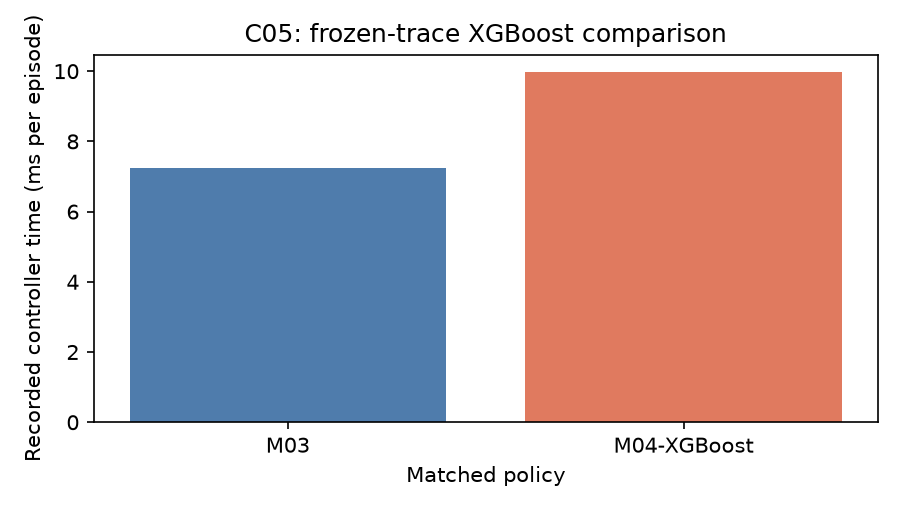

In [12]:
# Compare hash-verified canonical controller times under the same case, variant and seed.
labels = [primary_id, "M04-XGBoost"]
latencies = [records[primary_id]["metrics"]["controller_ms"], records["M04"]["metrics"]["controller_ms"]]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Matched policy")
ax.set_title(f"{sample_case}: frozen-trace XGBoost comparison")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 3 learned action scoring chart reads canonical M03/M04 records for C05, nominal variant and seed 40000 after the data boundary verifies their hashes. For this learned action scoring lesson, the stable figure describes recorded latency and intentionally makes no current-machine speed claim.

## Results

**Answer:** The learned action scoring level-3 comparison contains 2 fresh policy episodes plus 1 XGBoost M04 comparator on C05; those 3 matched runs do not establish population-level superiority for learned action scoring.

For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, The package checkpoints are separately released assets and are not committed in this product repository. For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, The displayed fitted-method outcomes are the hash-verified recorded evaluations, not a freshly refitted model. For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, For level 3 of learned action scoring on C05, A rate on designed families is not an estimate for arbitrary software tasks.


## Summary

For level 3 of learned action scoring on C05, At level 3, learned action scoring uses C05 to show how the released method behaves under one declared condition. For level 3 of learned action scoring on C05, Keep the observed outcome separate from a claim about general software-control intelligence.


## References

- [XGB](https://arxiv.org/abs/1603.02754)
- [GRU](https://arxiv.org/abs/1406.1078)
- [LINUCB](https://arxiv.org/abs/1003.0146)
